In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
import pickle
import os


In [106]:
### Read CSV
df = pd.read_csv('bank.csv')
print(df.shape)
print(df['deposit'].value_counts())
print(df.columns)
df.head()

(11162, 17)
deposit
no     5873
yes    5289
Name: count, dtype: int64
Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='str')


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [107]:
print(df.isnull().sum())  

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64


In [108]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [109]:
df['deposit'] = df['deposit'].map({'no': 0, 'yes': 1})
print(df['deposit'].value_counts())

deposit
0    5873
1    5289
Name: count, dtype: int64


In [110]:
for col in ['default', 'housing', 'loan']:
    df[col] = df[col].map({'no': 0, 'yes': 1})

In [111]:
### Turn the other text columns into numbers
text_cols = df.select_dtypes(exclude='number').columns.to_list()
print(text_cols)

df = pd.get_dummies(df, columns=text_cols, drop_first=True, dtype=int)
print(df.shape)


['job', 'marital', 'education', 'contact', 'month', 'poutcome']
(11162, 43)


In [112]:
X = df.drop('deposit', axis=1)
Y = df['deposit']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [113]:
### Train a tree with no limit (to see overfitting)
full_tree= DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, Y_train)

print('Depth:', full_tree.get_depth())
print('Training Accuracy:', full_tree.score(X_train, Y_train))
print('Testing Accuracy:', full_tree.score(X_test, Y_test))

Depth: 30
Training Accuracy: 1.0
Testing Accuracy: 0.7962382445141066


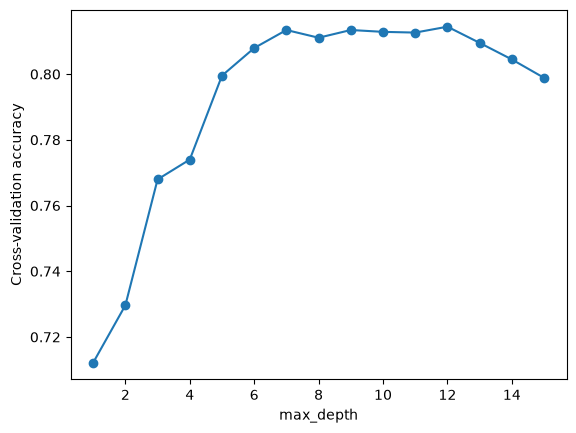

Best depth: 12


In [114]:
### Find the best max_depth
cv_scores = []
for d in range(1, 16):
    t= DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_scores.append(cross_val_score(t, X_train, Y_train, cv=5).mean())

plt.plot(range(1, 16), cv_scores, marker='o')
plt.xlabel('max_depth')
plt.ylabel('Cross-validation accuracy')
plt.show()


best_depth = int(np.argmax(cv_scores)) + 1
print("Best depth:", best_depth)


In [115]:
### Train the final tree
final_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
final_tree.fit(X_train, Y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

In [116]:
### Predict and evaluate
Y_pred = final_tree.predict(X_test)
Y_proba = final_tree.predict_proba(X_test)[:, 1]

print('Accuracy:', accuracy_score(Y_test, Y_pred))
print('Precision:', precision_score(Y_test, Y_pred))
print('Recall:', recall_score(Y_test, Y_pred))
print('F1 Score:', f1_score(Y_test, Y_pred))

Accuracy: 0.8284818629646216
Precision: 0.8157156220767072
Recall: 0.8241965973534972
F1 Score: 0.8199341795956746


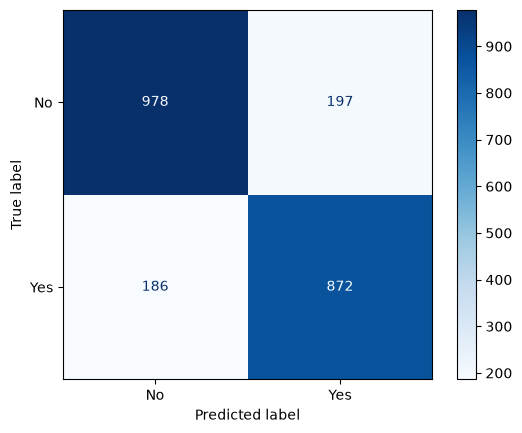

In [117]:
ConfusionMatrixDisplay.from_predictions(Y_test, Y_pred,
                                        display_labels=['No', 'Yes'], cmap='Blues')
plt.show()

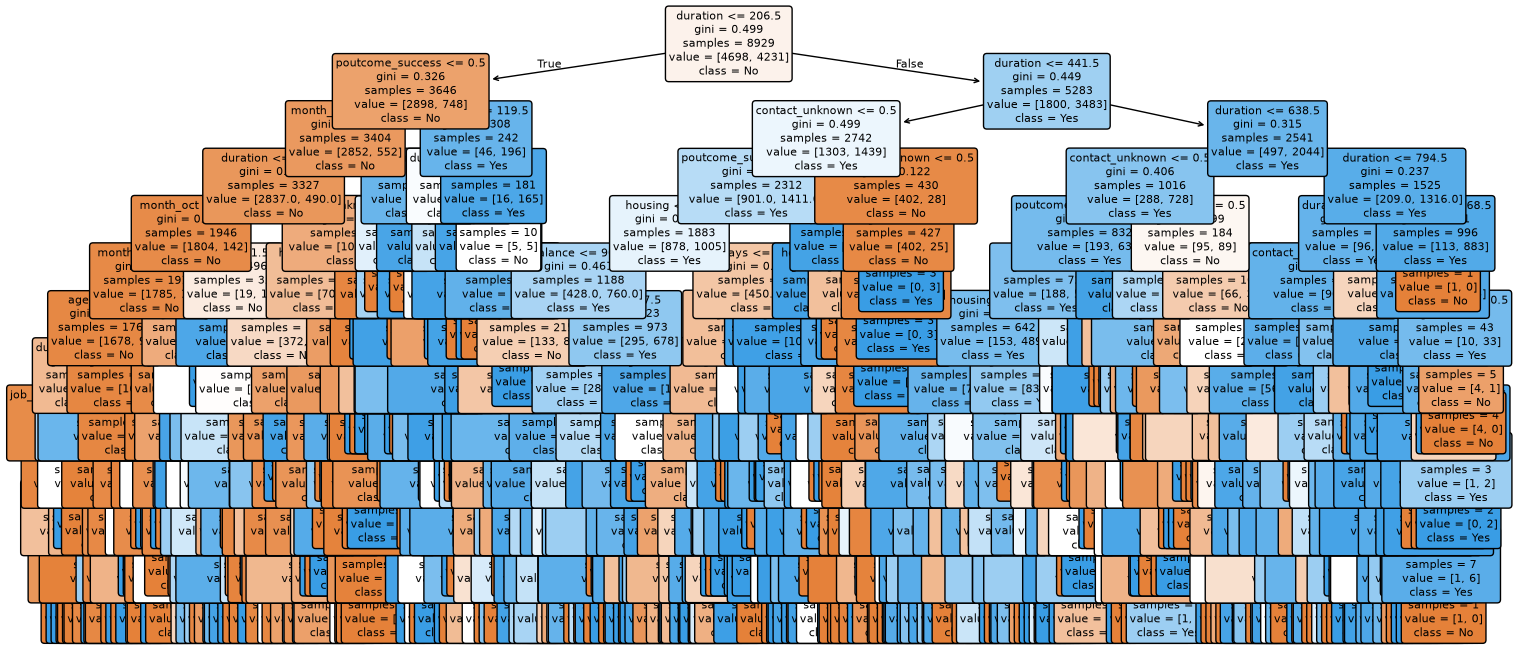

In [118]:
### Draw the tree

plt.figure(figsize=(18, 8))
plot_tree(final_tree, feature_names=X.columns, class_names=['No', 'Yes'],
          filled=True, rounded=True, fontsize=8, max_depth=12)
plt.show()

In [119]:
print(export_text(final_tree, feature_names=list(X.columns), max_depth=12))

|--- duration <= 206.50
|   |--- poutcome_success <= 0.50
|   |   |--- month_mar <= 0.50
|   |   |   |--- duration <= 129.50
|   |   |   |   |--- month_oct <= 0.50
|   |   |   |   |   |--- month_feb <= 0.50
|   |   |   |   |   |   |--- age <= 25.50
|   |   |   |   |   |   |   |--- duration <= 98.50
|   |   |   |   |   |   |   |   |--- job_unemployed <= 0.50
|   |   |   |   |   |   |   |   |   |--- month_jun <= 0.50
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |   |--- month_jun >  0.50
|   |   |   |   |   |   |   |   |   |   |--- job_student <= 0.50
|   |   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |   |   |--- job_student >  0.50
|   |   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |--- job_unemployed >  0.50
|   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |--- duration >  98.50
|   |   |   |   |   |   |   |   |--- duration <= 105.00
|   |

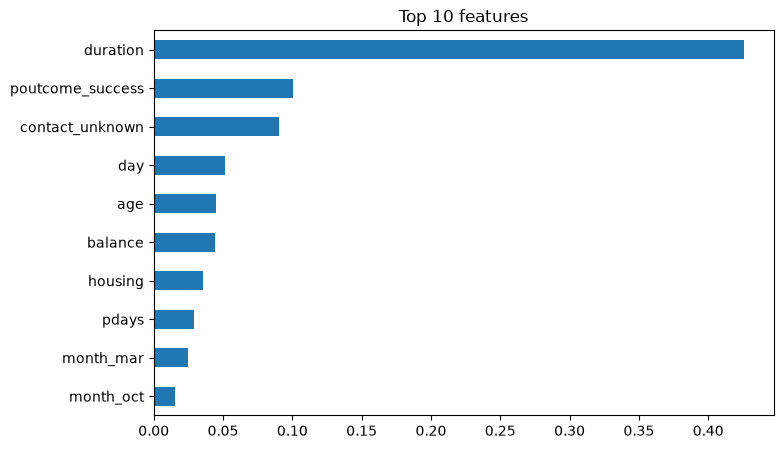

In [120]:
imp = pd.Series(final_tree.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Top 10 features')
plt.show()

In [121]:
X2 = X.drop(columns=['duration'])

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, Y, test_size=0.2, random_state=42, stratify=Y)

tree2 = DecisionTreeClassifier(max_depth=10, random_state=42)
tree2.fit(X2_train, y2_train)

print("Train:", round(tree2.score(X2_train, y2_train), 4))
print("Test :", round(tree2.score(X2_test, y2_test), 4))
print("Recall:", round(recall_score(y2_test, tree2.predict(X2_test)), 4))

Train: 0.7545
Test : 0.7009
Recall: 0.5539


In [122]:
### Save the model
with open('final_tree_model.pkl', 'wb') as file:
    pickle.dump(final_tree, file)
print("Model saved Successfully")

Model saved Successfully


In [123]:
### Open the model
with open('final_tree_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)
print("Model loaded Successfully")

Model loaded Successfully


In [124]:
## Check whether the model is working
print(os.path.exists('final_tree_model.pkl'))

True


In [125]:
print(loaded_model)
print('Model Depth: ', loaded_model.get_depth())
print('Number of Leaves: ', loaded_model.get_n_leaves())

DecisionTreeClassifier(max_depth=12, random_state=42)
Model Depth:  12
Number of Leaves:  455


In [126]:
y_pred_org = final_tree.predict(X_test)
y_pred_loaded = loaded_model.predict(X_test)

print("Original Model Predictions:", y_pred_org[:10]) 
print("Loaded Model Predictions:", y_pred_loaded[:10])

print("Predictions are the same:", (y_pred_org == y_pred_loaded).all())

Original Model Predictions: [1 1 1 0 1 0 0 0 1 1]
Loaded Model Predictions: [1 1 1 0 1 0 0 0 1 1]
Predictions are the same: True
